# 03 - Feature panel: satellite, weather and crop-condition paths

`data/processed/features_daily.parquet` has one row per geography (5 states plus the national `US` aggregate) and calendar day, Apr 1 - Oct 31, 2009-2026. Every value is an **as-of** value: it uses only data that had been published by that date (`modis_asof`, `weather_asof`, `usda_asof` record the observation each value comes from). `features_trading.parquet` is the same US panel restricted to ZCZ trading dates.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cornsat.config import DATA_PROCESSED, ROOT

REPORTS = ROOT / "reports"
SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
C1, C2, C3, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2,
    "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False, "lines.linewidth": 1.6,
})
pd.set_option("display.width", 160)

daily = pd.read_parquet(DATA_PROCESSED / "features_daily.parquet")
trading = pd.read_parquet(DATA_PROCESSED / "features_trading.parquet")
us = daily[daily["geo"] == "US"].copy()
us["md"] = us["date"].apply(lambda d: d.replace(year=2001))  # common x axis (2001 is not a leap year)
print("daily", daily.shape, "| US rows", len(us), "| trading", trading.shape)
print("geos:", sorted(daily["geo"].unique()), "| seasons", us["season"].min(), "-", us["season"].max())

daily (23112, 38) | US rows 3852 | trading (2679, 200)
geos: ['IA', 'IL', 'IN', 'MN', 'NE', 'US'] | seasons 2009 - 2026

## Seasonal paths: 2012 (drought), 2019 (wet, late planting), 2014 (normal)

Grey lines are all the other seasons. `ndvi_z` is the satellite signal (NDVI z-score against the 2003+ climatology). `ge_anom` is the USDA good/excellent rating minus normal (it is NaN before 2012 in the table, so 2009-2011 are not drawn there). `edd30_14d` is extreme-degree-days above 30 C over the last 14 days, and `precip_30d_anom` is 30-day precipitation relative to normal.

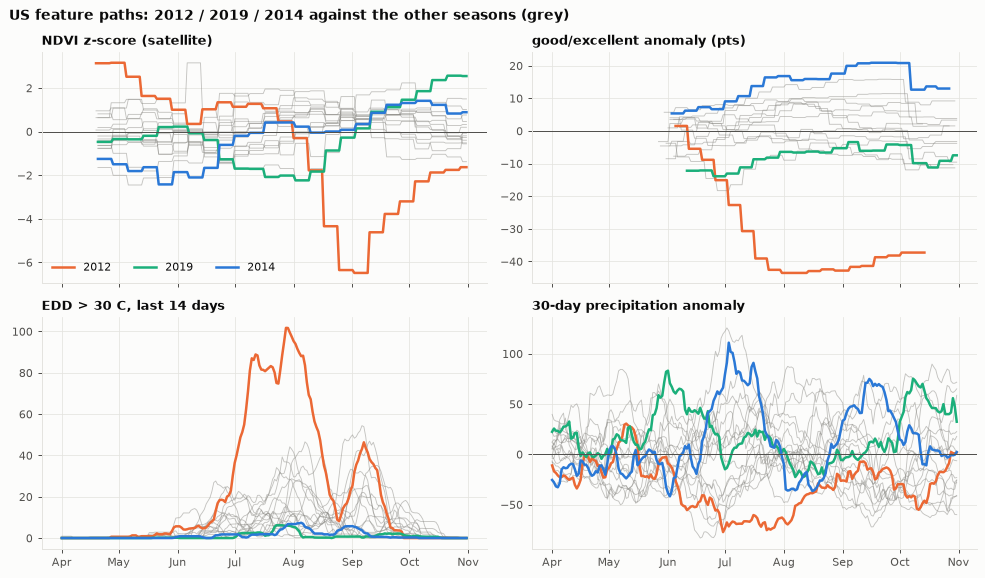

In [2]:
import matplotlib.dates as mdates
panels = [("ndvi_z", "NDVI z-score (satellite)"), ("ge_anom", "good/excellent anomaly (pts)"),
          ("edd30_14d", "EDD > 30 C, last 14 days"), ("precip_30d_anom", "30-day precipitation anomaly")]
hl = {2012: C2, 2019: C3, 2014: C1}
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for ax, (c, lab) in zip(axes.ravel(), panels):
    for s, d in us.groupby("season"):
        if s not in hl:
            ax.plot(d["md"], d[c], color=NEUTRAL, lw=0.7, alpha=0.5)
    for s, col in hl.items():
        d = us[us["season"] == s]
        ax.plot(d["md"], d[c], color=col, lw=2, label=str(s))
    ax.set_title(lab, loc="left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    if c in ("ndvi_z", "ge_anom", "precip_30d_anom"):
        ax.axhline(0, color=INK2, lw=0.8)
axes[0, 0].legend(loc="lower left", ncol=3)
fig.suptitle("US feature paths: 2012 / 2019 / 2014 against the other seasons (grey)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

## Correlation with the final yield surprise

The target is the final national yield minus an OLS trend fitted on 1990..Y-1 (`reports/stageA_targets.csv`, built by `cornsat.model`). Each bar is the Pearson correlation across seasons between the US feature **as known on Aug 1 / Sep 1** and that season's surprise. This is a full-sample, descriptive look: with at most 17 seasons it is noisy and it is not the walk-forward test, which is in `04_backtest.ipynb`. Seasons where a feature is NaN are dropped (n is shown).

                group  Aug 1 corr  Aug 1 n  Sep 1 corr  Sep 1 n
ndvi_z              S        0.23       17        0.77       16
evi_anom_cum        S       -0.05       17        0.19       16
ndvi_trend_anom     S        0.54       17        0.26       16
edd30_cum           W       -0.76       17       -0.77       17
precip_30d_anom     W        0.49       17        0.61       17
gdd_cum_anom        W       -0.62       17       -0.59       17
ge                  C        0.84       17        0.89       17
ge_anom             C        0.92       14        0.96       14
ge_chg_2w           C        0.62       17        0.26       17

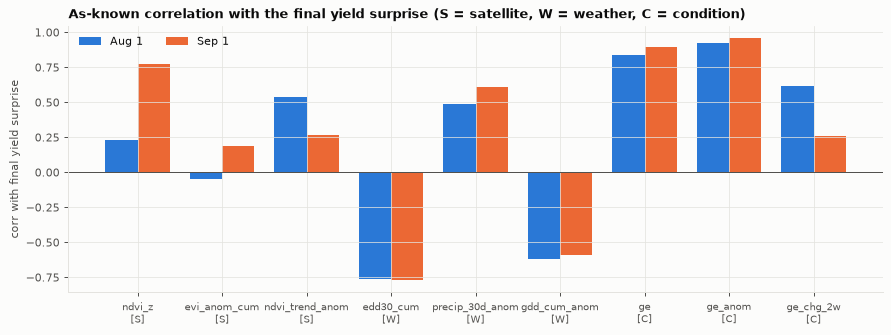

In [3]:
tg = pd.read_csv(REPORTS / "stageA_targets.csv").set_index("season")["surprise"]
feats = ["ndvi_z", "evi_anom_cum", "ndvi_trend_anom", "edd30_cum", "precip_30d_anom", "gdd_cum_anom",
         "ge", "ge_anom", "ge_chg_2w"]
group = {"ndvi_z": "S", "evi_anom_cum": "S", "ndvi_trend_anom": "S", "edd30_cum": "W",
         "precip_30d_anom": "W", "gdd_cum_anom": "W", "ge": "C", "ge_anom": "C", "ge_chg_2w": "C"}
res = {}
for lab, (m, dd) in {"Aug 1": (8, 1), "Sep 1": (9, 1)}.items():
    snap = us[(us["date"].dt.month == m) & (us["date"].dt.day == dd)].set_index("season")
    j = snap[feats].join(tg.rename("surprise"), how="inner")
    res[lab] = pd.DataFrame({"corr": [j[f].corr(j["surprise"]) for f in feats],
                             "n": [int(j[[f, "surprise"]].dropna().shape[0]) for f in feats]}, index=feats)
tbl = pd.concat(res, axis=1).round(2)
tbl.columns = [f"{a} {b}" for a, b in tbl.columns]
tbl.insert(0, "group", pd.Series(group))
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(feats)); w = 0.38
ax.bar(x - w / 2, res["Aug 1"]["corr"], w, color=C1, label="Aug 1")
ax.bar(x + w / 2, res["Sep 1"]["corr"], w, color=C2, label="Sep 1")
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(x); ax.set_xticklabels([f"{f}\n[{group[f]}]" for f in feats], fontsize=8)
ax.set_ylabel("corr with final yield surprise")
ax.set_title("As-known correlation with the final yield surprise (S = satellite, W = weather, C = condition)", loc="left")
ax.legend(loc="upper left", ncol=2)
fig.tight_layout()
tbl

Reading the bars: condition (C) is the strongest as-known signal on both dates (`ge_anom` 0.92 on Aug 1 and 0.96 on Sep 1, n = 14; `ge` 0.84 and 0.89), and cumulative extreme heat (`edd30_cum`, -0.76 and -0.77) is the best weather feature. The satellite features are weak on Aug 1 (`ndvi_z` 0.23, `evi_anom_cum` -0.05; `ndvi_trend_anom` 0.54 is the exception) and `ndvi_z` only reaches 0.77 on Sep 1, when condition and weather already carry the same information. A high correlation here is not predictive value: the walk-forward test in Phase 6 finds S adds nothing beyond W and C (W+C RMSE 7.1 vs W+C+S 7.6 over the 7 snapshots).

## Why the satellite signal lags

Two delays stack, and both are structural rather than a data-quality problem:

1. **Publication lag, about 14 days.** MODIS MOD13Q1/MYD13Q1 composites reach the Planetary Computer archive roughly two weeks after the composite ends. The feature panel encodes this as `MODIS_LAG_DAYS = 14` in `cornsat.features`: a composite becomes usable on `end_date + 14` (the 10-day `modis.LAG_DAYS` stored with the raw table is deliberately overridden by this more conservative value).
2. **16-day composite.** Each product is the best observation in a 16-day window, with Terra and Aqua offset by 8 days. A heat or dry spell that starts mid-window is averaged with healthy days, so vegetation stress only shows once it is long and severe enough to dominate the composite.

Together the satellite reading on a given day typically describes canopy conditions from 2 to 4 weeks earlier (median age about 18 days, measured below). The cell below measures this on the US panel: `modis_age_days` is the gap between the date and the end of the latest composite that was available. By contrast, weather arrives with a 3-day lag (NASA POWER) and USDA condition ratings every Monday, describing the previous week. In the 2012 drought, 14-day EDD crossed 20 on Jun 27 and the G/E rating was more than 10 points below normal by Jun 26, while US `ndvi_z` only fell below -1 on Aug 9 (see `04_backtest.ipynb`). That is the core reason the satellite adds nothing beyond weather and crop condition.

MODIS age at use, Jun-Aug US rows (n=1656): median 18 d, mean 17.9 d, 10-90% 14-21 d, max 51 d

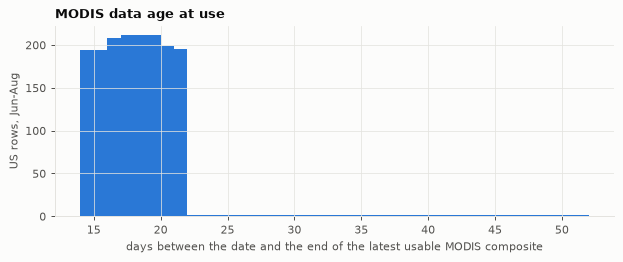

In [4]:
jja = us[us["date"].dt.month.isin([6, 7, 8])]
age = jja["modis_age_days"].dropna()
print(f"MODIS age at use, Jun-Aug US rows (n={len(age)}): median {age.median():.0f} d, "
      f"mean {age.mean():.1f} d, 10-90% {age.quantile(.1):.0f}-{age.quantile(.9):.0f} d, max {age.max():.0f} d")
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(age, bins=range(int(age.min()), int(age.max()) + 2), color=C1)
ax.set_xlabel("days between the date and the end of the latest usable MODIS composite")
ax.set_ylabel("US rows, Jun-Aug")
ax.set_title("MODIS data age at use", loc="left")
fig.tight_layout()